This file was me playing around with things I found in the qiskit guidebook.

In [1]:
import math
pi = math.acos(-1)

In [2]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

sampler = StatevectorSampler()
result = sampler.run([qc], shots=1024).result()
print(result[0].data.meas.get_counts())

{'00': 506, '11': 518}


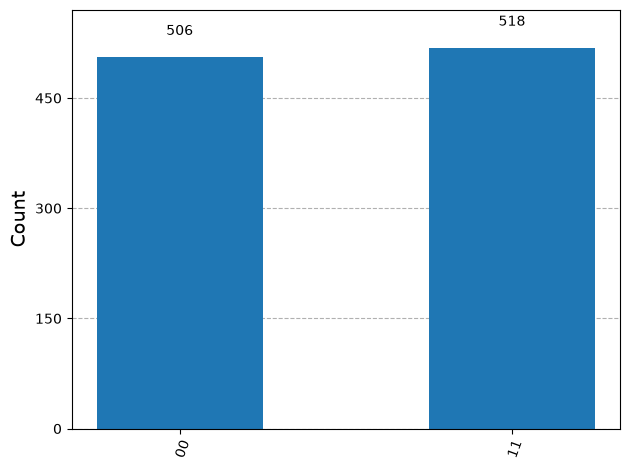

In [3]:
# Uncomment lines 2 and 8 if you are not using Python in a Jupyter notebook
# import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

counts = result[0].data.meas.get_counts()
plot_histogram(counts)

# plt.show()

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService

In [5]:
QiskitRuntimeService.save_account(
    # For `token`, use the 44-character API_KEY you created
    # and saved from the IBM Quantum Platform Home dashboard
    token="73mluAAsyE33n5UBPs6hlwvw3Q_D8KNni011O92Sl27p",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/e58031486bb541deb2b33099854ac881:5198e064-a7e0-4abc-850c-8f6bcaaa04f2::", # Optional
    overwrite=True
)

In [6]:
# Run every time you need the service
service = QiskitRuntimeService()

# First install: pip install qiskit qiskit-aer
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

In [7]:
qc = QuantumCircuit(1, 1)
# No gate: remain in |0>
qc.measure(0, 0)

sim = AerSimulator()
result = sim.run(qc, shots=256).result()
print(result.get_counts())

{'0': 256}


In [8]:
qc = QuantumCircuit(1, 1)
qc.x(0)  # Flip 0 to 1
qc.measure(0, 0)

sim = AerSimulator()
result = sim.run(qc, shots=256).result()
print(result.get_counts())

{'1': 256}


In [9]:
qc = QuantumCircuit(1, 1)
qc.h(0)  # Create superposition
qc.measure(0, 0)

sim = AerSimulator()
result = sim.run(qc, shots=256).result()
print(result.get_counts())

{'1': 145, '0': 111}


In [10]:
qc = QuantumCircuit(1, 1)
qc.h(0)  # Create superposition
qc.measure(0, 0)

sim = AerSimulator()
result = sim.run(qc, shots=256).result()
print(result.get_counts())

{'0': 125, '1': 131}


[CircuitInstruction(operation=Instruction(name='h', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=()), CircuitInstruction(operation=Instruction(name='h', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=()), CircuitInstruction(operation=Instruction(name='cx', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>), clbits=()), CircuitInstruction(operation=Instruction(name='rx', num_qubits=1, num_clbits=0, params=[0.39269908169872414]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=()), CircuitInstruction(operation=Instruction(name='rz', num_qubits=1, num_clbits=0, params=[0.7853981633974483]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=()), CircuitInstruction(operation=Instruction(name='barrier', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>), c

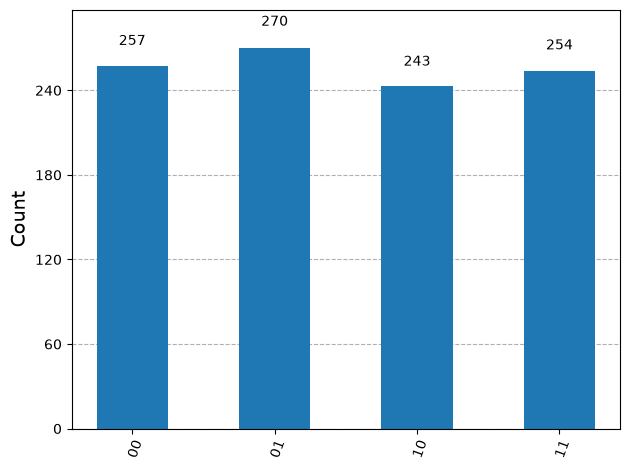

In [11]:
qc = QuantumCircuit(2)
qc.h(0)
qc.h(1)
qc.cx(0,1)
qc.rx(pi/8,1)
qc.rz(pi/4,1)
qc.measure_all()
print(qc.data)
print(qc.draw())

sampler = StatevectorSampler()
result = sampler.run([qc], shots=1024).result()
print(result[0].data.meas.get_counts())

counts = result[0].data.meas.get_counts()
plot_histogram(counts)

Some things about the QuantumCircuit class
- The number you use as a parameter is the number of qubits involved.
- `H(<index>)` places a superposition gate on that index. It does a 50/50 on every shot.
- `X(<index>)` places a one-qubit Pauli-X gate on that index. By rotating the bit pi radians, it flips the qubit.
- `Y(<index>)` places a one-qubit Pauli-Y gate on that index. By rotating the bit pi radians, it does a bit and phase flip.
- `Z(<index>)` places a one-qubit Pauli-Z gate on that index. By rotating the bit pi radians, it does a phase flip.
- `I(<index>)` places an identity gate on that index. It does nothing.
- `P(<theta>,<index>)` places a phase gate on that index. It rotates the bit on the Z axis by theta.
- `CX(<ind1>,<ind2>)` is whatever a Controlled X-Gate is. It does an XOR on the second index.
- `draw()` prints out a diagram of the circuit so far or something.
- `measure()` prints qubits as bits.